# CANNY PROCESSING

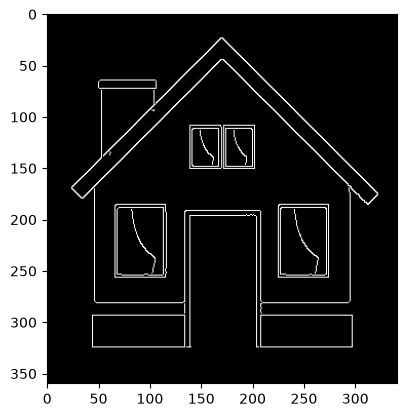

In [499]:
import cv2 as cv
import matplotlib.pyplot as plt
# convert to gray
import cv2
img = cv2.imread("test2.jpg") 
t_lower = 100
t_upper = 200 
aperture_size = 5
L2Gradient = True 
edges = cv2.Canny(img, t_lower, t_upper, L2gradient = L2Gradient )
plt.imshow(edges, cmap ='grey')
# plt.axis('off')
plt.show()

In [468]:
grad_x = cv.Sobel(edges, cv.CV_64F, 1, 0, ksize=3)
grad_y = cv.Sobel(edges, cv.CV_64F, 0, 1, ksize=3)

In [469]:
grad_x

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(626, 470))

In [470]:
magnitude = cv.magnitude(grad_x, grad_y)

In [471]:
magnitude

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(626, 470))

(626, 470)


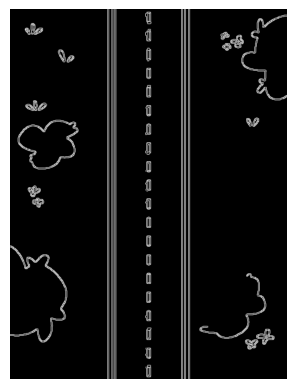

In [472]:
magnitude_norm = cv.normalize(
    magnitude, None, 0, 255, cv.NORM_MINMAX, dtype=cv.CV_8U
)
print(magnitude_norm.shape)
plt.imshow(magnitude_norm, cmap='grey')
plt.axis('off')
plt.show()

# Hough transform

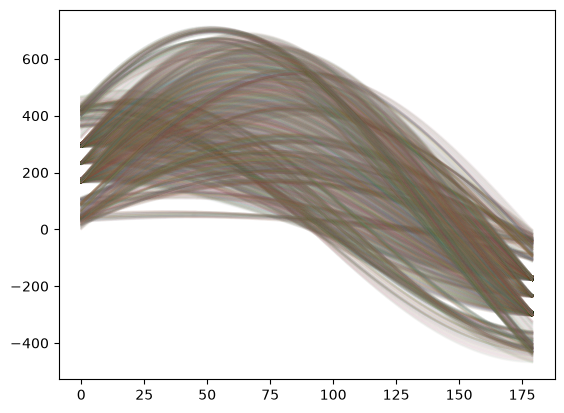

In [473]:
# edges = magnitude_norm
import numpy as np
y_axis, x_axis = np.nonzero(edges)
thetas = np.linspace(0, np.pi, 180)
p_ranges = []
for i in range(len(x_axis)):
    p = x_axis[i]*np.cos(thetas) + y_axis[i]*np.sin(thetas)
    p_ranges.append(p)

for i in range(len(p_ranges)):
    plt.plot(p_ranges[i], alpha = 0.02)
plt.show()

# Accumulator (vote Matrix)

In [474]:
arr =np.array([ [1,2],
 [3,4],
 [5,6]])

arr[[0,1], 1] + 1

array([3, 5])

In [475]:
array1 = np.array([1,2,4,4])
print(np.where(array1 == 0))

(array([], dtype=int64),)


In [476]:
RATIO = np.pi / 180
THETA_STEP = np.pi / 100
DISTANCE_STEP = 2
diag = np.sqrt(img.shape[0]**2 + img.shape[1]**2) # Giá trị lơn nhất của `p` là đương chéo
theta_range = np.arange(0, np.pi, THETA_STEP)
distance_range = np.arange(0, diag  + 3, DISTANCE_STEP)
ACCUMULATOR = np.zeros((len(distance_range), len(theta_range)), dtype=np.uint64)

for x, y in zip(x_axis, y_axis):
    distances = x*np.cos(theta_range) + y*np.sin(theta_range)
    distances = distances.astype(int)
    for theta_index in range(len(theta_range)):
        distance_index = np.argwhere(distance_range == distances[theta_index])
        if len(distance_index) == 0:
            continue
        # print(f"Distance: {distances[theta_index]}, Theta: {theta_range[theta_index]}")
        ACCUMULATOR[distance_index, theta_index] += 1
        
ACCUMULATOR


array([[ 2,  0,  0, ..., 16, 16,  7],
       [ 3,  0,  0, ...,  9,  6,  3],
       [ 3,  0,  0, ..., 17,  5,  3],
       ...,
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0],
       [ 0,  0,  0, ...,  0,  0,  0]], shape=(393, 100), dtype=uint64)

In [477]:
sorted(ACCUMULATOR.flat, reverse=True)[:10]

[np.uint64(626),
 np.uint64(626),
 np.uint64(626),
 np.uint64(326),
 np.uint64(96),
 np.uint64(96),
 np.uint64(96),
 np.uint64(96),
 np.uint64(96),
 np.uint64(95)]

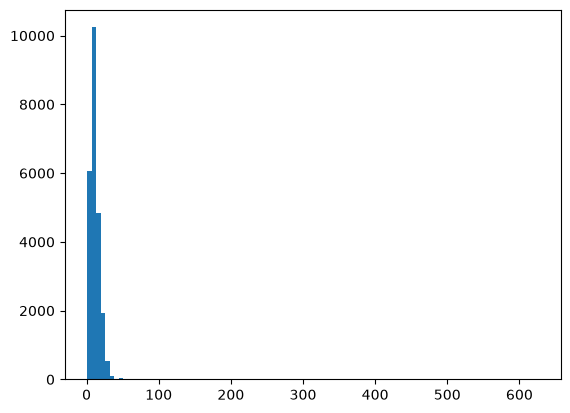

In [478]:
import matplotlib.pyplot as plt
plt.hist(ACCUMULATOR.flat[ACCUMULATOR.flat > 0], bins=100)
plt.show()

In [479]:
top_peaks = np.argwhere(ACCUMULATOR > 10)

In [480]:
top_peaks

array([[  0,  50],
       [  0,  51],
       [  0,  52],
       ...,
       [351,  32],
       [352,  30],
       [353,  26]], shape=(11862, 2))

In [481]:
sorted_top_peaks = sorted(top_peaks, key=lambda x: ACCUMULATOR[x[0], x[1]], reverse=True)

In [482]:
sorted_top_peaks

[array([83,  0]),
 array([89,  0]),
 array([148,   0]),
 array([116,   0]),
 array([89,  1]),
 array([90,  1]),
 array([92,  1]),
 array([152,   1]),
 array([154,   1]),
 array([91,  1]),
 array([153,   1]),
 array([155,   1]),
 array([151,   1]),
 array([87,  1]),
 array([88,  1]),
 array([93,  1]),
 array([95,  1]),
 array([148,   1]),
 array([149,   1]),
 array([157,   1]),
 array([94,  1]),
 array([150,   1]),
 array([156,   1]),
 array([ 0, 79]),
 array([118,   0]),
 array([117,   0]),
 array([121,  33]),
 array([96,  1]),
 array([140,  13]),
 array([42, 75]),
 array([90,  2]),
 array([92,  2]),
 array([94,  2]),
 array([95,  2]),
 array([97,  2]),
 array([98,  2]),
 array([99,  2]),
 array([100,   2]),
 array([101,   2]),
 array([109,  35]),
 array([152,   2]),
 array([154,   2]),
 array([156,   2]),
 array([157,   2]),
 array([158,   2]),
 array([159,   2]),
 array([160,   2]),
 array([161,   2]),
 array([162,   2]),
 array([163,   2]),
 array([164,   2]),
 array([89,  2]),
 arr

In [483]:
def return_line(peaks, theta_range, distance_range):
    lines = []
    for peak in peaks:
        # if abs(peak[1] - 90) < 1e-5:
        #     # slope = 0
        #     x0 = distance_range[peak[0]]
        #     y0 = 0
        #     x1 = distance_range[peak[0]]
        #     y1 = img.shape[0]
        #     lines.append(((x0, y0), (x1, y1)))
        # elif abs(peak[1] - 0) < 1e-5:
        #     # slope = inf
        #     x0 = 0
        #     y0 = distance_range[peak[0]]
        #     x1 = img.shape[1]
        #     y1 = distance_range[peak[0]]
        #     lines.append(((x0, y0), (x1, y1)))
        # else:
        distance = distance_range[peak[0]]
        theta = theta_range[peak[1]]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * distance
        y0 = b * distance
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        lines.append(((x0, y0), (x1, y1)))
    return lines

In [484]:
def draw_lines(img, peaks, theta_range, distance_range):
    lines = return_line(peaks, theta_range, distance_range)
    for line in lines:
        cv.line(img, (int(line[0][0]), int(line[0][1])), (int(line[1][0]), int(line[1][1])), (255, 0, 0), 2)
    return img

# Draw lines that depend on the `Accumulator`
- Find list of peakest point
- drawline draw line all of those

sample1: [83  0]
slope: -inf, intercept: 83


/tmp/ipykernel_40276/1637893003.py:3: RuntimeWarning: divide by zero encountered in scalar divide
  slope_ = -np.cos(sample1[1]*RATIO) / np.sin(sample1[1]*RATIO)
/tmp/ipykernel_40276/1637893003.py:11: RuntimeWarning: invalid value encountered in multiply
  plt.plot(range_, slope_ * range_ + intercept_, color='red')


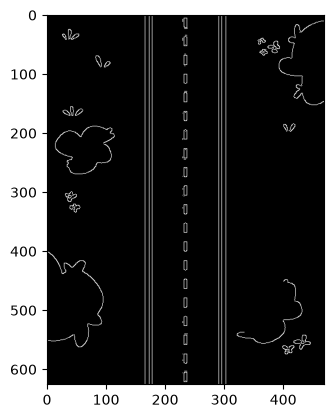

In [485]:
sample1 = sorted_top_peaks[0]
print(f'sample1: {sample1}')
slope_ = -np.cos(sample1[1]*RATIO) / np.sin(sample1[1]*RATIO)
if np.sin(sample1[1]*RATIO) != 0:
    intercept_ = sample1[0] / np.sin(sample1[1] * RATIO)
else:
    intercept_ = sample1[0]
print(f'slope: {slope_}, intercept: {intercept_}')
range_ = np.linspace(0, img.shape[0], 1000)

plt.plot(range_, slope_ * range_ + intercept_, color='red')
plt.imshow(edges, cmap='gray')
# plt.scatter(x_axis, y_axis, s=1)
plt.show()

In [486]:
sorted_top_peaks

[array([83,  0]),
 array([89,  0]),
 array([148,   0]),
 array([116,   0]),
 array([89,  1]),
 array([90,  1]),
 array([92,  1]),
 array([152,   1]),
 array([154,   1]),
 array([91,  1]),
 array([153,   1]),
 array([155,   1]),
 array([151,   1]),
 array([87,  1]),
 array([88,  1]),
 array([93,  1]),
 array([95,  1]),
 array([148,   1]),
 array([149,   1]),
 array([157,   1]),
 array([94,  1]),
 array([150,   1]),
 array([156,   1]),
 array([ 0, 79]),
 array([118,   0]),
 array([117,   0]),
 array([121,  33]),
 array([96,  1]),
 array([140,  13]),
 array([42, 75]),
 array([90,  2]),
 array([92,  2]),
 array([94,  2]),
 array([95,  2]),
 array([97,  2]),
 array([98,  2]),
 array([99,  2]),
 array([100,   2]),
 array([101,   2]),
 array([109,  35]),
 array([152,   2]),
 array([154,   2]),
 array([156,   2]),
 array([157,   2]),
 array([158,   2]),
 array([159,   2]),
 array([160,   2]),
 array([161,   2]),
 array([162,   2]),
 array([163,   2]),
 array([164,   2]),
 array([89,  2]),
 arr

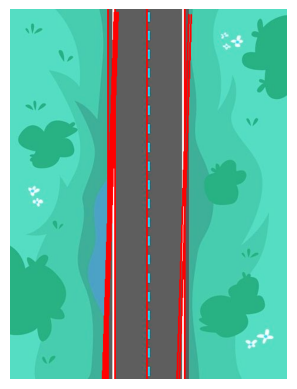

In [487]:
list_a = sorted_top_peaks[:10]
drawn_img = draw_lines(img.copy(), list_a, theta_range, distance_range)
plt.imshow(drawn_img)
plt.axis('off')
plt.xlim(0, img.shape[1])
plt.ylim(img.shape[0], 0)
plt.show()

# Các hàm cần làm

In [ ]:
#kernel mau

def convolve2d(img, kernel, mode="same"):
        kh, kw = kernel.shape
        ph, pw = kh // 2, kw // 2
        P = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="constant")
        K = kernel[::-1, ::-1]
        out = np.zeros(img.shape, float)
        for i in range(kh):
            for j in range(kw):
                out += K[i, j] * P[i:i + img.shape[0], j:j + img.shape[1]]
        return out


def _local_max(A, r):

    # Tính toán trong một vùng xem có số vote cao hơn trong cái slide-window
    # Dể giảm các các line gần sát nhau để tối ưu mỗi vùng là một đường line duy nhất đó

    P = np.pad(A, r, mode="constant", constant_values=-np.inf)
    H, W = A.shape
    out = np.full(A.shape, -np.inf)
    for dy in range(2 * r + 1):
        for dx in range(2 * r + 1):
            np.maximum(out, P[dy:dy + H, dx:dx + W], out=out)
    return out

def _gaussian_kernel(sigma):
    # dùng tạo ra một kernel hỗ trợ tích chập cho việc làm mượt lại lại phần ACCUMULATOR
    # Giúp cho các số vote nó ko bị chênh lệt quá nhiều  + tránh nhiễu các phiếu vote
    # tạo hình guassian hình chuông theo chuẩn
    r = max(1, int(np.ceil(3 * sigma)))
    x = np.arange(-r, r + 1)
    g = np.exp(-x ** 2 / (2 * sigma ** 2))
    g /= g.sum()
    return np.outer(g, g)

def hough_accumulate(edges, theta_range, rho_range, n_theta, n_rho,
                     grad_dir=None, delta_deg=None):
    
    
    dist_step  = (rho_range[1] - rho_range[0]) / (n_rho - 1) # delta `p`
    thetas = np.linspace(theta_range[0], theta_range[1], n_theta) # dãy phân bố các giá trị của `theta` 
    distances = np.linspace(rho_range[0], rho_range[1], n_rho) # dãy phân bố của `p`


    y_s, x_s = np.nonzero(edges) # lấy các index của các của các điểm pixel là cạnh-

    g = None
    if grad_dir is not None:
        g = grad_dir[y_s, x_s]
        delta = np.deg2rad(delta_deg if delta_deg is not None else 180.0)

    cos_t, sin_t = np.cos(thetas), np.sin(thetas)

    ACCUMULATOR = np.zeros((len(distances), len(thetas)), dtype=np.uint64) # Để lưu trữ các phiếu vote cho của các đường hough

    for k, (x, y) in enumerate(zip(x_s, y_s)):
        dist = x * cos_t + y * sin_t # biến đổi các đườngn mx + b = y -> các đường hough
        dist_idx = np.rint((dist - rho_range[0]) / dist_step).astype(int)
        isInRange = (dist_idx >= 0) & (dist_idx < n_rho) 
        if g is not None and not np.isnan(g[k]):
            diff = (thetas - g[k] + np.pi / 2) % np.pi - np.pi / 2
            isInRange = isInRange & (np.abs(diff) <= delta)
        theta_index = np.nonzero(isInRange)[0]
        # Cắt nhỏ các đường hough line ra các thành các đường ô nhỏ nếu thuộc về các range trong `ACCUMULATOR`
        ACCUMULATOR[dist_idx[theta_index], theta_index] += 1


    return ACCUMULATOR, thetas, distances

def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0, thetas=None, rhos=None):
    As = A.astype(float)
    if smooth_sigma and smooth_sigma > 0:
        # Làm mượt các điểm vote liên tiếp thành dạng hình chuông
        As = convolve2d(As, _gaussian_kernel(smooth_sigma), mode="same")

    is_peak = (As >= _local_max(As, nms_radius)) & (As > 0) # Lất một vùng +-r lấy các cạnh vote nổi trội thay vì lấy tất cả các điểm vote gần bằng nhau
    dist_index, theta_index = np.nonzero(is_peak)
    order = np.argsort(-As[dist_index, theta_index], kind="stable")[:n_peaks] # Sắp xếp lại các số vote nổi trội và lấy các số ứng viên `n_peak`
    dist_index, theta_index = dist_index[order], theta_index[order] 

    # trả về giá trị
    result = []
    for d, t in zip(dist_index, theta_index):
        dho = rhos[d] if rhos is not None else d
        theta = thetas[t] if thetas is not None else t
        result.append((float(dho), float(theta), float(A[d, t])))
    return result


def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8,
                     n_lines=10, delta_deg=10.0,
                     coarse_theta_step_deg=1.0, coarse_rho_step=1.0,
                     nms_radius=3, smooth_sigma=1.0, window_steps=2,
                     dedup_rho=3.0, dedup_theta_deg=3.0):
    height, width = edges.shape
    diag = float(np.hypot(height, width))

    d_theta = np.deg2rad(coarse_theta_step_deg)
    dist_step = float(coarse_rho_step)
    n_theta = int(round(np.pi / d_theta))
    n_rho = int(round(2 * diag / dist_step)) + 1

    # ---- mức 0 (thô) ----
    A, thetas, rhos = hough_accumulate(
        edges, (0.0, np.pi - np.pi / n_theta), (-diag, diag), n_theta, n_rho,
        grad_dir, delta_deg)
    cands = [(d, t) for d, t, _ in
                find_peaks(A, n_lines, nms_radius, smooth_sigma, thetas, rhos)]

    # ---- các mức mịn ----
    for _ in range(1, n_levels):
        w_t, w_d = window_steps * d_theta, window_steps * dist_step


        d_theta /= refine_factor
        dist_step /= refine_factor
        nt = int(round(2 * w_t / d_theta)) + 1
        nd = int(round(2 * w_d / dist_step)) + 1
        new = []
        for d0, t0 in cands:
            A, thetas, rhos = hough_accumulate(
                edges, (t0 - w_t, t0 + w_t), (d0 - w_d, d0 + w_d), nt, nd,
                grad_dir, delta_deg)
            pk = find_peaks(A, 1, nms_radius=1, smooth_sigma=0.0,
                            thetas=thetas, rhos=rhos)
            new.append((pk[0][0], pk[0][1]) if pk else (d0, t0))
        cands = new

    # ---- loại trùng ----
    final = []
    for r, t in cands:
        t = t % np.pi if t >= np.pi or t < 0 else t
        dup = False
        for r2, t2 in final:
            dt = abs((t - t2 + np.pi / 2) % np.pi - np.pi / 2)
            if abs(r - r2) < dedup_rho and np.rad2deg(dt) < dedup_theta_deg:
                dup = True
                break
        if not dup:
            final.append((r, t))
    return final



    

Tổng phiếu: có gradient 373792  |  không gradient 531500
Số đường: có gradient 10, không gradient 10, multiscale 10
  multiscale: rho= 136.463  theta= 45.000°
  multiscale: rho= 150.709  theta= 45.000°
  multiscale: rho=-144.210  theta=168.750°
  multiscale: rho= 203.944  theta=  0.000°
  multiscale: rho= 192.197  theta= 11.250°
  multiscale: rho= 280.923  theta= 90.000°
  multiscale: rho=-103.971  theta=135.000°
  multiscale: rho= 255.930  theta= 90.000°
  multiscale: rho= 184.949  theta= 90.000°
  multiscale: rho= 292.919  theta= 90.000°
Đã lưu test_image_result.png


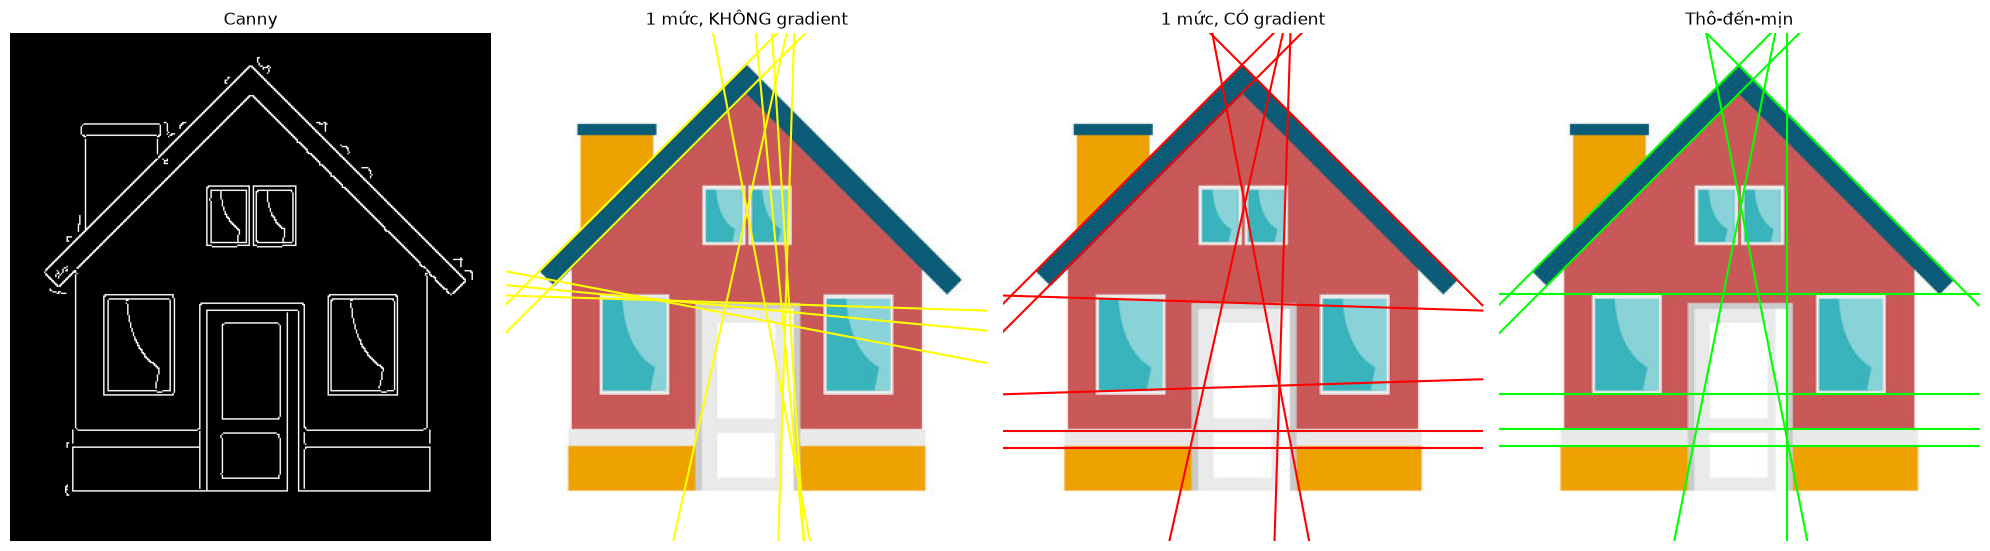